# 03 · Explainability: SHAP and LIME for the NGBoost forecast
* **SHAP**: Shapley values from cooperative game theory, each feature's fair share of the gap between this prediction and the average prediction. Additive (contributions + base value = prediction), consistent, gives both **global** (all seasons) and **local** (one season) views.
* **LIME**: perturbs one input many times, fits a small weighted linear model around it, and reads its coefficients. Model-agnostic and intuitive, but **local only** and dependent on random sampling and on how features are binned.

**What is explained.** The selected model is **NGBoost**, which predicts two things for every district-season: the expected yield μ (kg/ha) and the spread σ (uncertainty). Both are explained:
* Sections 1 to 6 explain **μ, the expected yield** (global SHAP, dependence, district sensitivity, case studies, LIME, SHAP vs LIME).
* Section 7 explains **σ, the uncertainty**: which conditions make a season harder to forecast, and therefore raise P(shortfall) even when μ is unchanged.
* Section 8 checks whether a different model family (the best tree model, with `TreeExplainer`) learns the same drivers.

The tuned NGBoost uses ridge regressions as base learners, so the boosted ensemble collapses to one linear model per parameter (μ and log σ). Its SHAP values are therefore **exact**: coefficient × (feature value − background mean), computed in `src/explain.py`. The model trained on seasons ≤ 2015 is explained on the **test** seasons.

In [1]:
import sys, warnings, json
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, shap
from src import config as C, explain as E
from src.features import TARGET, feature_list
from src.modeling import temporal_split
from src.probabilistic import SigmaView, shortfall_threshold_values
from src import train as T

df = T.load_table(); features = feature_list(df); train, test = temporal_split(df)
meta = json.loads((C.ARTIFACTS / "app_metadata.json").read_text())
best_name = meta["best_model"]
model = joblib.load(C.MODELS / "best_model_train_only.joblib")     # NGBoost, calibrated, trained on <= 2015
print("Explaining:", best_name, "| NGBoost:", E.is_ngboost(model), "| sigma calibration k =", round(model.sigma_scale, 3))
FIG = C.FIGURES

Explaining: NGBoost | NGBoost: True | sigma calibration k = 1.29


## 1. Global SHAP: which features drive yield forecasts?

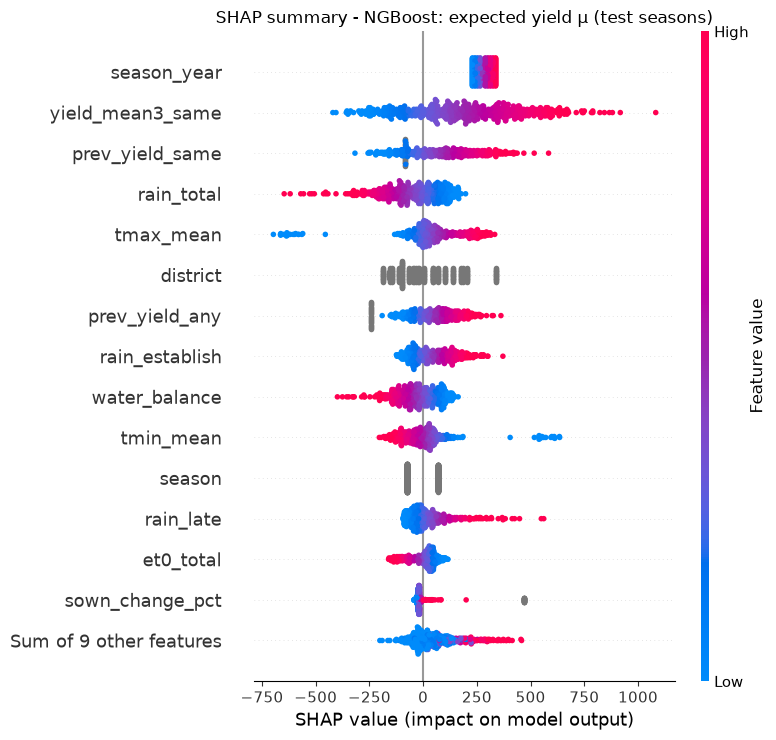

In [2]:
X_explain = test[features]
ex_main = E.shap_explanation(model, X_explain, features, background=train)
shap.plots.beeswarm(ex_main, max_display=15, show=False)
plt.title(f"SHAP summary - {best_name}: expected yield μ (test seasons)"); plt.tight_layout()
plt.savefig(FIG / "shap_beeswarm.png", dpi=150, bbox_inches="tight"); plt.show()

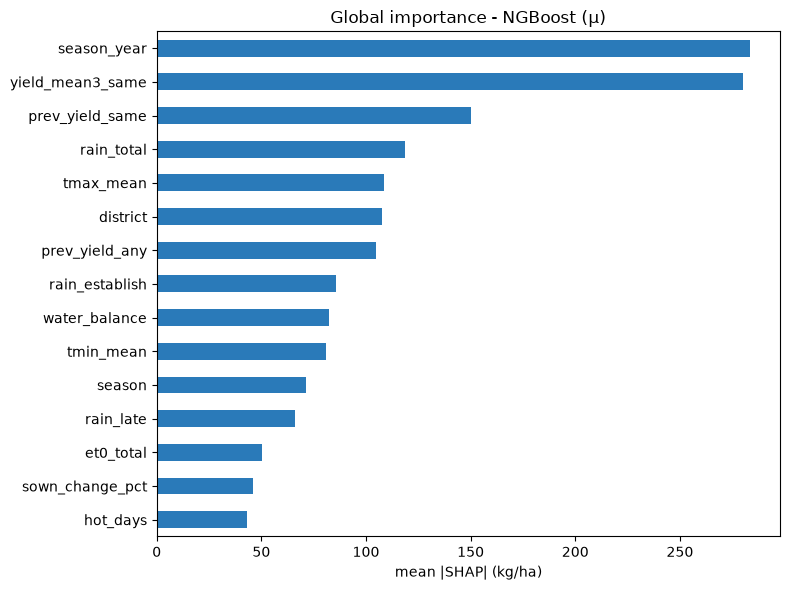

,mean_abs_shap_kg_ha
season_year,283.6
yield_mean3_same,280.3
prev_yield_same,150.0
rain_total,118.8
tmax_mean,108.6
district,107.5
prev_yield_any,104.8
rain_establish,85.5
water_balance,82.3
tmin_mean,81.1


In [3]:
imp = E.shap_importance(ex_main)
plt.figure(figsize=(8, 6)); imp.head(15)[::-1].plot.barh(color="#2a7ab9")
plt.xlabel("mean |SHAP| (kg/ha)"); plt.title(f"Global importance - {best_name} (μ)"); plt.tight_layout()
plt.savefig(FIG / "shap_bar.png", dpi=150); plt.show()
imp.round(1).to_frame("mean_abs_shap_kg_ha")

## 2. Dependence plots: shape of the effects and interactions

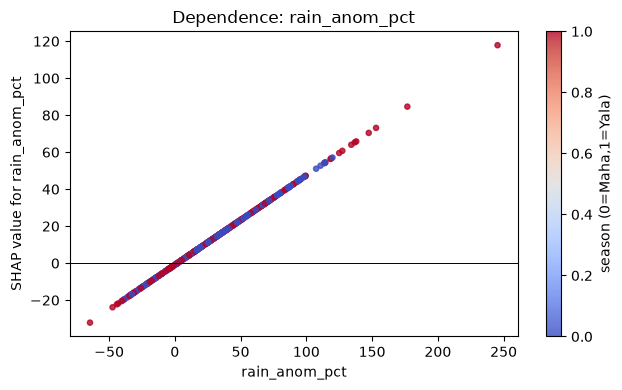

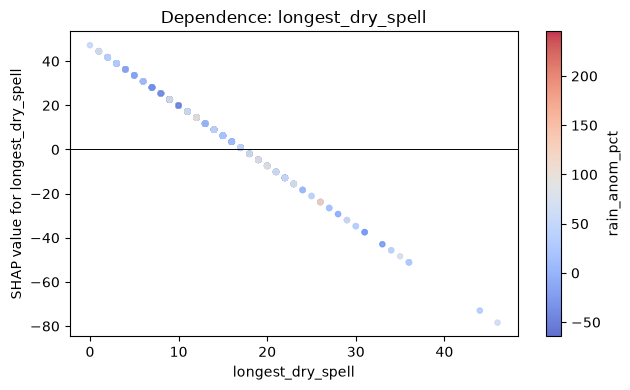

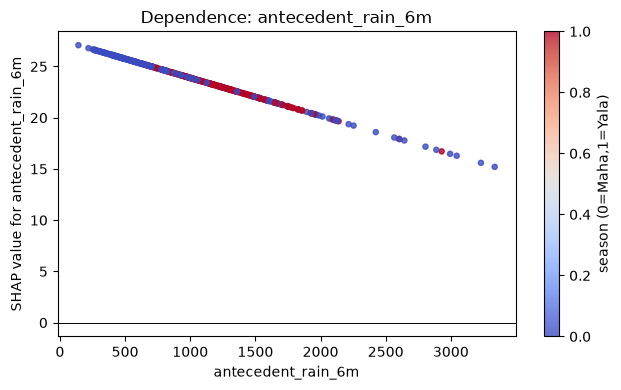

In [4]:
for f, inter in [("rain_anom_pct", "season"), ("longest_dry_spell", "rain_anom_pct"), ("antecedent_rain_6m", "season")]:
    if f in features:
        j = features.index(f)
        vals = ex_main[:, j]
        colour = test[inter] if pd.api.types.is_numeric_dtype(test[inter]) else (test[inter] == "Yala").astype(int)
        plt.figure(figsize=(6.5, 4))
        sc = plt.scatter(test[f], vals.values, c=colour, s=14, cmap="coolwarm", alpha=.8)
        plt.colorbar(sc, label=inter + (" (0=Maha,1=Yala)" if inter == "season" else ""))
        plt.axhline(0, c="k", lw=.7); plt.xlabel(f); plt.ylabel(f"SHAP value for {f}")
        plt.title(f"Dependence: {f}"); plt.tight_layout(); plt.savefig(FIG / f"shap_dep_{f}.png", dpi=150); plt.show()

## 3. SHAP by district group: is irrigation a buffer?

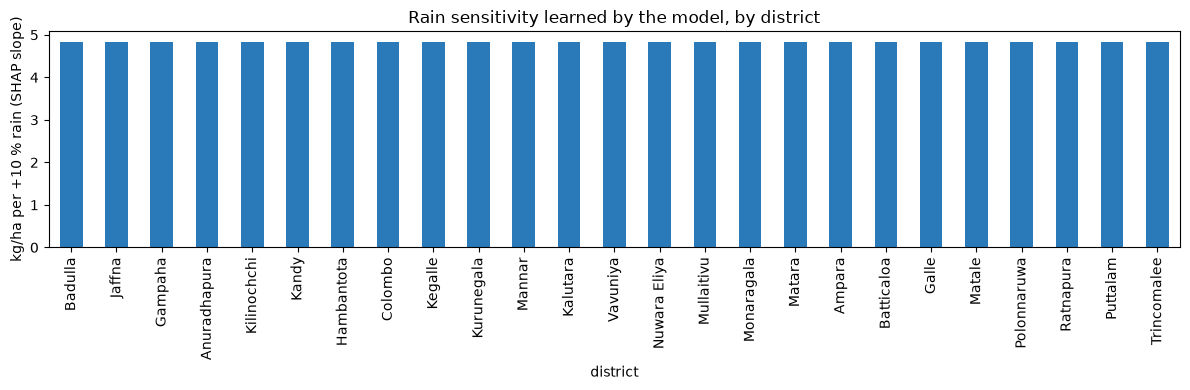

In [5]:
j = features.index("rain_anom_pct")
shap_rain = pd.DataFrame({"district": test.district, "rain_anom": test.rain_anom_pct, "shap": ex_main.values[:, j]}).dropna()
slope = (shap_rain.groupby("district").apply(lambda g: np.polyfit(g.rain_anom, g.shap, 1)[0] * 10 if len(g) > 3 else np.nan)
         .dropna().sort_values())
plt.figure(figsize=(12, 4)); slope.plot.bar(color="#2a7ab9")
plt.ylabel("kg/ha per +10 % rain (SHAP slope)"); plt.title("Rain sensitivity learned by the model, by district")
plt.tight_layout(); plt.savefig(FIG / "shap_rain_sensitivity.png", dpi=150); plt.show()

## 4. Local explanations: three case studies

In [6]:
p = model.predict(test[features]); err = p - test[TARGET]
cases = {
    "Largest over-prediction": int(np.argmax(err)),
    "Driest season":           int(test.rain_anom_pct.idxmin()),
    "Typical season":          int((err.abs()).sub(err.abs().median()).abs().idxmin()),
}
case_df = test.loc[list(cases.values()), ["district", "season", "season_year", TARGET, "rain_anom_pct", "fertilizer_crisis"]]
case_df.insert(0, "case", list(cases.keys())); case_df["predicted"] = p[list(cases.values())].round(0)
mu_c, sd_c = model.predict_normal(test.iloc[list(cases.values())][features])
case_df["80% interval"] = [f"{a - 1.2816 * b:,.0f} – {a + 1.2816 * b:,.0f}" for a, b in zip(mu_c, sd_c)]
case_df["P(shortfall)"] = model.prob_below(test.iloc[list(cases.values())][features],
                                           shortfall_threshold_values(test.iloc[list(cases.values())])).round(2)
case_df

,case,district,season,season_year,yield_kg_ha,rain_anom_pct,fertilizer_crisis,predicted,80% interval,P(shortfall)
268,Largest over-prediction,Vavuniya,Maha,2021,2373.0,15.630748,1,5100.0,"3,986 – 6,214",0.12
67,Driest season,Nuwara Eliya,Yala,2017,3619.0,-64.509689,0,4024.0,"3,058 – 4,989",0.09
204,Typical season,Kalutara,Yala,2020,3380.0,44.306281,0,3051.0,"2,570 – 3,532",0.14


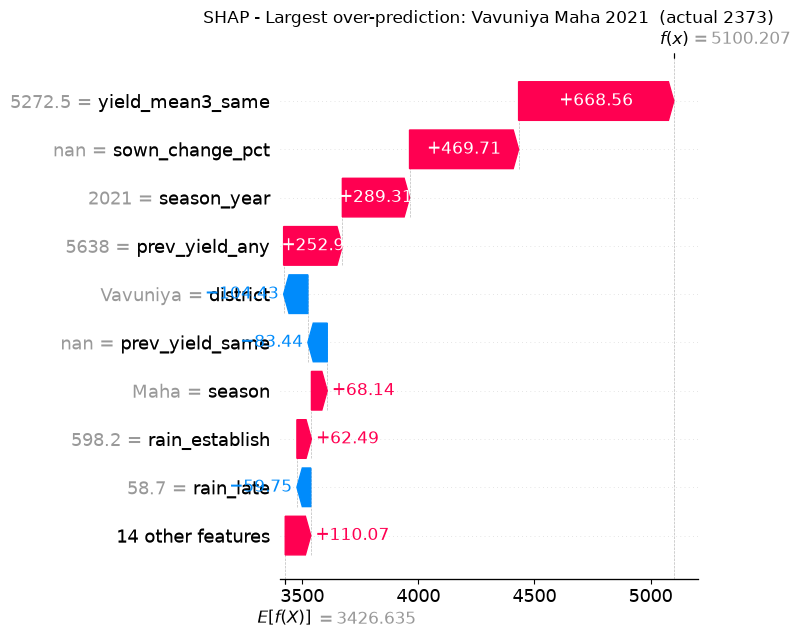

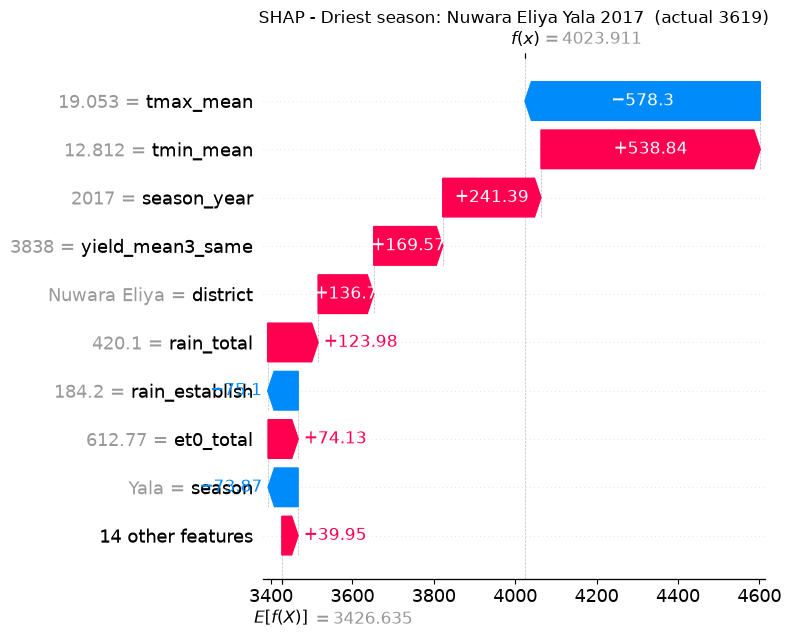

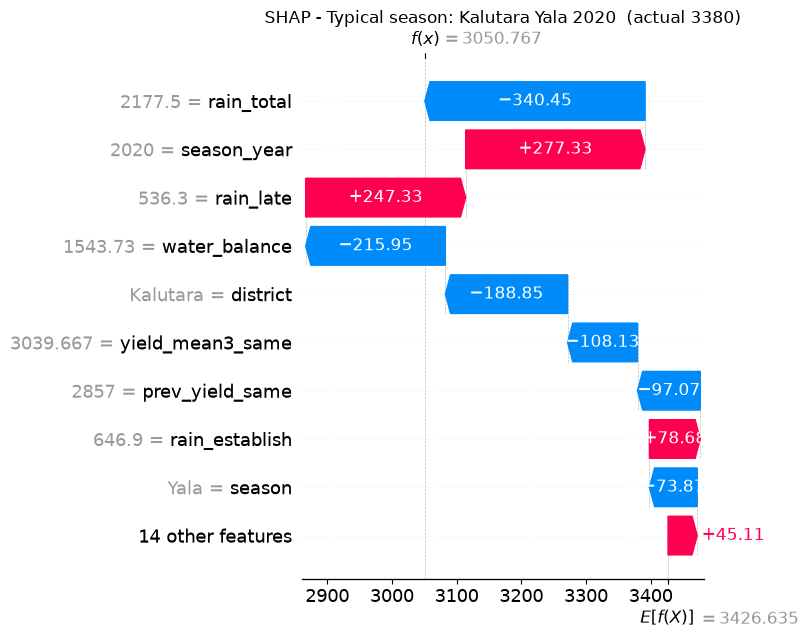

In [7]:
for label, i in cases.items():
    r = test.iloc[i]
    shap.plots.waterfall(ex_main[i], max_display=10, show=False)
    plt.title(f"SHAP - {label}: {r.district} {r.season} {r.season_year}  (actual {r[TARGET]:.0f})")
    plt.tight_layout(); plt.savefig(FIG / f"shap_waterfall_{T.slug(label)}.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. LIME on the same cases

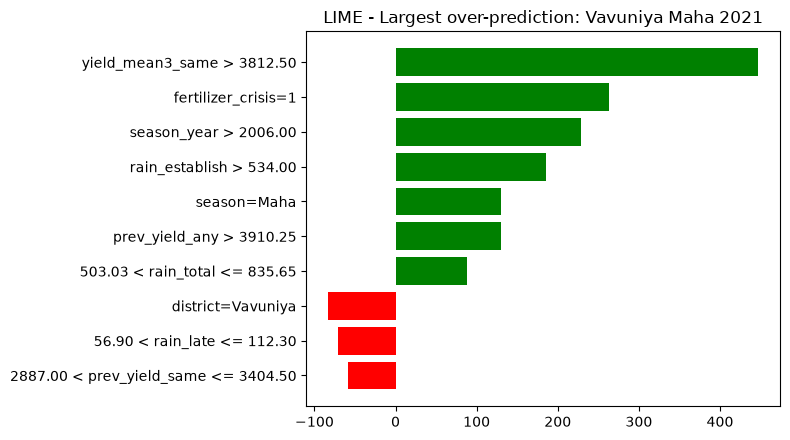

model prediction 5100  |  LIME local surrogate 4432  |  surrogate R2 0.30


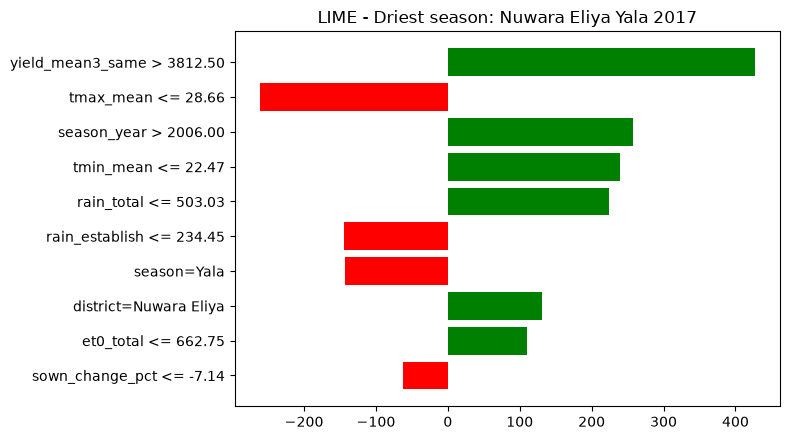

model prediction 4024  |  LIME local surrogate 4110  |  surrogate R2 0.41


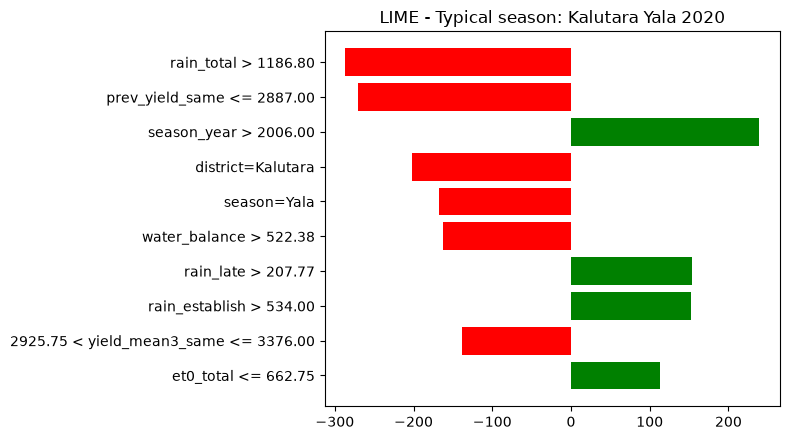

model prediction 3051  |  LIME local surrogate 3061  |  surrogate R2 0.29


In [8]:
bundle = E.lime_explainer(model, train[features], features)
lime_exps = {}
for label, i in cases.items():
    exp = E.lime_explain_row(model, train[features], test.iloc[[i]], features, explainer_bundle=bundle)
    lime_exps[label] = exp
    fig = exp.as_pyplot_figure(); fig.set_size_inches(8, 4.5)
    r = test.iloc[i]
    plt.title(f"LIME - {label}: {r.district} {r.season} {r.season_year}")
    plt.tight_layout(); plt.savefig(FIG / f"lime_{T.slug(label)}.png", dpi=150); plt.show()
    print(f"model prediction {model.predict(test.iloc[[i]][features])[0]:.0f}  |  LIME local surrogate {exp.local_pred[0]:.0f}  |  surrogate R2 {exp.score:.2f}")

## 6. SHAP vs LIME

In [9]:
for label, i in cases.items():
    print(label)
    display(E.compare_shap_lime(ex_main[i], lime_exps[label], top=6))

Largest over-prediction


,SHAP rank,LIME rank
1,yield_mean3_same,yield_mean3_same
2,sown_change_pct,fertilizer_crisis
3,season_year,season_year
4,prev_yield_any,rain_establish
5,district,season
6,prev_yield_same,prev_yield_any


Driest season


,SHAP rank,LIME rank
1,tmax_mean,yield_mean3_same
2,tmin_mean,tmax_mean
3,season_year,season_year
4,yield_mean3_same,tmin_mean
5,district,rain_total
6,rain_total,rain_establish


Typical season


,SHAP rank,LIME rank
1,rain_total,rain_total
2,season_year,prev_yield_same
3,rain_late,season_year
4,water_balance,district
5,district,season
6,yield_mean3_same,water_balance


In [10]:
# LIME stability: rerun with different random seeds - SHAP (TreeExplainer) is deterministic
i = cases["Typical season"]
tops = []
for seed in range(5):
    e = E.lime_explain_row(model, train[features], test.iloc[[i]], features, seed=seed)
    tops.append([c for c, _ in e.as_list()[:3]])
pd.DataFrame(tops, columns=["1st", "2nd", "3rd"], index=[f"seed {s}" for s in range(5)])

,1st,2nd,3rd
seed 0,rain_total > 1186.80,prev_yield_same <= 2887.00,district=Kalutara
seed 1,rain_total > 1186.80,season_year > 2006.00,prev_yield_same <= 2887.00
seed 2,prev_yield_same <= 2887.00,rain_total > 1186.80,season_year > 2006.00
seed 3,rain_total > 1186.80,season_year > 2006.00,prev_yield_same <= 2887.00
seed 4,rain_total > 1186.80,prev_yield_same <= 2887.00,water_balance > 522.38


| | SHAP (TreeExplainer) | LIME |
|---|---|---|
| Scope | Global + local | Local only |
| Theory | Shapley values; additive, consistent | Local linear surrogate on perturbed samples |
| Determinism | Exact and repeatable for trees | Varies with random seed and binning |
| Output form | kg/ha contribution per feature | Weight per *condition* (e.g. `rain_anom_pct <= -20`) |
| Cost | Fast for trees; slow (sampling) for other models | Fast, any model |
| Weakness | Splits credit between correlated features | Neighbourhood definition is arbitrary; can be unstable |

## 7. What drives the uncertainty? SHAP for σ
NGBoost's second output is the spread σ. SHAP values here are on **log σ**, so they combine multiplicatively: a value of +0.10 widens the forecast distribution by about 10 %. A wider distribution means a less certain forecast and, for the same μ, a higher probability of falling below the shortfall threshold.

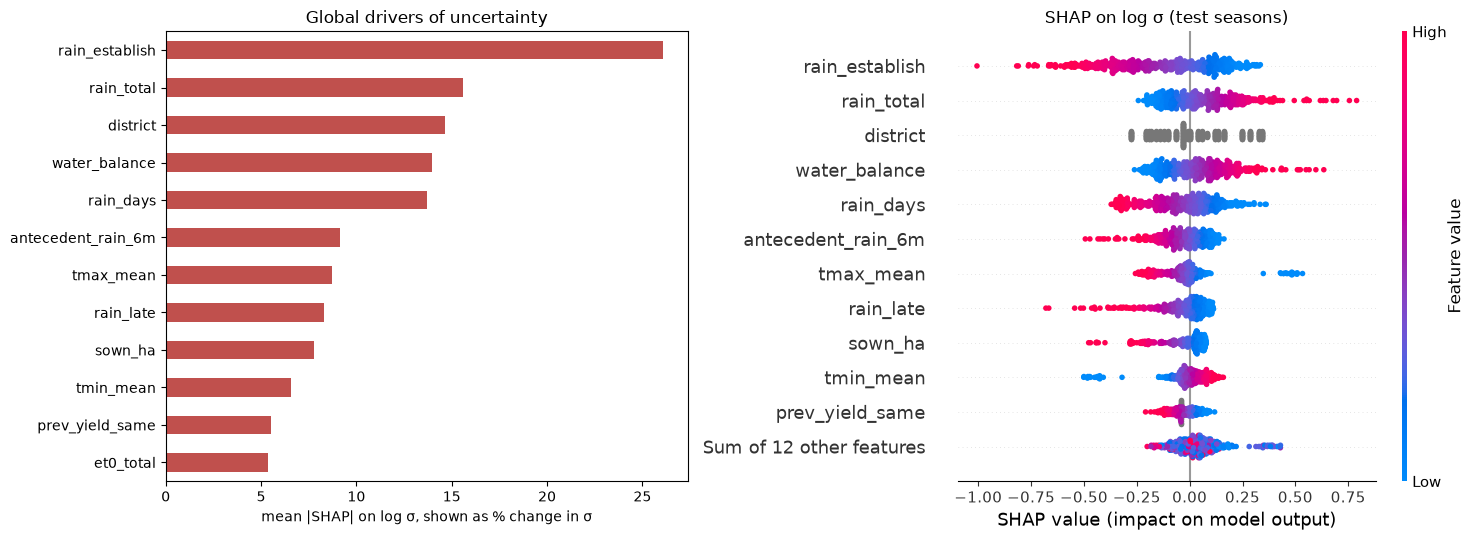

Mean predicted σ by district (kg/ha):
district
Galle           298.0
Kurunegala      298.0
Kalutara        306.0
Matara          307.0
Ampara          325.0
Puttalam        326.0
Kandy           329.0
Anuradhapura    329.0
Gampaha         331.0
Kegalle         335.0
Colombo         338.0
Ratnapura       357.0
Monaragala      359.0
Hambantota      373.0
Matale          381.0
Trincomalee     394.0
Polonnaruwa     399.0
Badulla         414.0
Batticaloa      423.0
Mullaitivu      525.0
Jaffna          586.0
Mannar          617.0
Vavuniya        632.0
Nuwara Eliya    637.0
Kilinochchi     692.0


In [11]:
ex_sig = E.shap_explanation(SigmaView(model), X_explain, features, background=train)
imp_sig = E.shap_importance(ex_sig)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
(100 * (np.exp(imp_sig.head(12)) - 1))[::-1].plot.barh(ax=ax[0], color="#c0504d")
ax[0].set_xlabel("mean |SHAP| on log σ, shown as % change in σ"); ax[0].set_title("Global drivers of uncertainty")
plt.sca(ax[1]); shap.plots.beeswarm(ex_sig, max_display=12, show=False, plot_size=None)
ax[1].set_title("SHAP on log σ (test seasons)")
plt.tight_layout(); plt.savefig(FIG / "shap_sigma.png", dpi=150, bbox_inches="tight"); plt.show()
sig_by_d = pd.Series(model.predict_sigma(X_explain), index=test.district).groupby(level=0).mean().sort_values()
print("Mean predicted σ by district (kg/ha):"); print(sig_by_d.round(0).to_string())

## 8. Do other model families learn the same drivers?
`TreeExplainer` on the best tree ensemble (exact Shapley values for trees) gives an independent check of what drives the forecast.

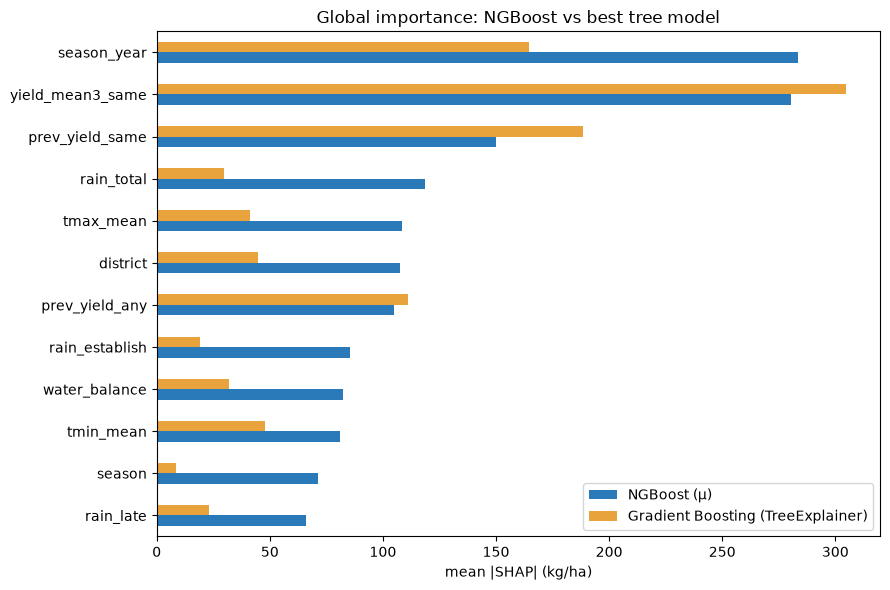

Spearman rank correlation of importances: 0.64


,NGBoost (μ),Gradient Boosting (TreeExplainer)
season_year,283.6,164.4
yield_mean3_same,280.3,304.5
prev_yield_same,150.0,188.5
rain_total,118.8,29.7
tmax_mean,108.6,41.3
district,107.5,44.6
prev_yield_any,104.8,111.1
rain_establish,85.5,19.1
water_balance,82.3,32.0
tmin_mean,81.1,48.0


In [12]:
cv = pd.read_csv(C.ARTIFACTS / "cv_results.csv")
tree_name = next(m for m in cv.model if m in ("XGBoost", "LightGBM", "Random Forest", "Gradient Boosting"))
tree = joblib.load(C.MODELS / f"{T.slug(tree_name)}.joblib")
ex_tree = E.shap_explanation(tree, X_explain, features)
both = pd.DataFrame({f"{best_name} (μ)": E.shap_importance(ex_main), f"{tree_name} (TreeExplainer)": E.shap_importance(ex_tree)})
both = both.sort_values(f"{best_name} (μ)", ascending=False).head(12)
both[::-1].plot.barh(figsize=(9, 6), color=["#2a7ab9", "#e8a33d"]); plt.xlabel("mean |SHAP| (kg/ha)")
plt.title("Global importance: NGBoost vs best tree model"); plt.tight_layout()
plt.savefig(FIG / "shap_bar_selected_model.png", dpi=150); plt.show()
print("Spearman rank correlation of importances:",
      round(pd.DataFrame({"a": E.shap_importance(ex_main), "b": E.shap_importance(ex_tree)}).corr("spearman").iloc[0, 1], 2))
both.round(1)

## 9. Summary: what the model learned

**Most influential features (expected yield μ)**

- `season_year` (mean |SHAP| 284 kg/ha) carries the long-run rise in yields.
- `yield_mean3_same` (280) and `prev_yield_same` (150) anchor the forecast to the district's recent seasons.
- Weather moves the forecast by about 80 to 120 kg/ha: `rain_total` (119), `tmax_mean` (109), `rain_establish` (86), `water_balance` (82) and `tmin_mean` (81).
- `district` (108) captures fixed differences between the irrigated dry zone and the wet zone.

**Agreement with domain knowledge**

- More seasonal rain lowers the forecast; rain at crop establishment raises it. This matches the EDA: irrigation buffers drought, but heavy late rain brings flooding, cloud cover and disease.
- Hotter days raise the forecast; warmer nights lower it. Warm nights are a known cause of lower rice yields, because the plant loses more carbon to respiration.
- Maha is forecast slightly higher than Yala (+68 against -74 kg/ha), in line with Maha being the main season.
- `fertilizer_crisis` gets zero weight because it is 0 in every training season. That is why Vavuniya Maha 2021 was forecast at 5,100 kg/ha against an actual 2,373.

**Uncertainty (σ)**

- σ is highest in Kilinochchi, Nuwara Eliya, Vavuniya, Mannar and Jaffna (586 to 692 kg/ha) and lowest in Galle and Kurunegala (about 300).
- These districts have the most volatile yields and the most gaps in the record (notebook 01). The same expected drop therefore gives a higher shortfall probability there.
- Good rain at crop establishment narrows the forecast distribution.

**Cross-checks**

- Gradient boosting with `TreeExplainer` puts the same history features at the top (Spearman rank correlation 0.64), but relies less on weather.
- SHAP and LIME agree on the top feature in two of the three cases, and their top three overlap in all three.
- LIME's local fit is weak (surrogate R² 0.29 to 0.41) and its ranking shifts with the random seed.
- LIME even ranks `fertilizer_crisis` second for Vavuniya, although the model gives it zero weight.
- SHAP is exact for this model, so it is the reference. LIME is a readable cross-check.